In [29]:
import geopandas as gpd
import pandas as pd
from sklearn import linear_model
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

In [38]:
gdf_kt_route = gpd.read_file(r"D:\Profiles\Tim\Documents\Community Response\Codebase\data\kintore-tealing-collected-evidence\spatial\route_lines_f44d4b876709.geojson").to_crs("epsg:27700")

In [4]:
gdf_data = gpd.read_file(r"D:\Profiles\Tim\Documents\Community Response\Codebase\validation\temporary_gdf.geojson")
gdf_data = gdf_data.set_index("2021 output area")
gdf_data

,aggregation_small,LSOA21NM,aggregation_medium,council,empirical,modelled,squared_error,p_children,mean_adult_age,p_level_4,p_green_heating,p_married,p_born_in_UK,p_L1_to_L6,p_religion,p_nonchristian_religion,p_owned,p_car_drive_commute,total_route_exposure,geometry
2021 output area,,,,,,,,,,,,,,,,,,,,
S00139512,S01014253,0.0,S02002646,S12000041,0.0,0.954179,0.910458,0.311765,48.589744,0.173554,0.000000,0.289157,0.780488,0.157025,0.357143,0.053571,0.211765,0.533333,0.328992,"MULTIPOLYGON (((360204.798 759660.783, 360115...."
S00139498,S01014253,0.0,S02002646,S12000041,0.0,0.896055,0.802914,0.234043,47.055556,0.328571,0.000000,0.293478,0.921348,0.432432,0.382979,0.000000,0.573034,0.619048,0.183282,"MULTIPOLYGON (((360229.881 759863.237, 360224 ..."
S00139489,S01014254,0.0,S02002646,S12000041,0.0,0.029794,0.000888,0.312500,45.259740,0.162500,0.000000,0.271028,0.864865,0.256098,0.289720,0.018692,0.477064,0.627451,0.256110,"MULTIPOLYGON (((360308.15 759886.07, 360322.04..."
S00139523,S01014251,0.0,S02002646,S12000041,0.0,0.949706,0.901942,0.172727,46.120879,0.095238,0.000000,0.112245,0.913978,0.144578,0.387755,0.142857,0.163265,0.500000,0.144862,"MULTIPOLYGON (((360439.001 759296, 360406.83 7..."
S00139505,S01014252,0.0,S02002646,S12000041,0.0,0.254148,0.064591,0.146067,51.105263,0.148649,0.000000,0.241379,0.865169,0.166667,0.337209,0.000000,0.356322,0.512195,0.166509,"MULTIPOLYGON (((360421.023 759743.892, 360404...."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
S00139256,S01013827,0.0,S02002572,S12000034,0.0,0.734549,0.539563,0.401869,42.937500,0.392405,0.000000,0.594595,0.938596,0.567568,0.198198,0.000000,0.945946,0.692308,0.012861,"MULTIPOLYGON (((387504 785403, 387448 785457, ..."
S00139257,S01013826,0.0,S02002572,S12000034,0.0,0.349508,0.122156,0.051948,53.328767,0.301205,0.000000,0.223529,0.903614,0.324675,0.392857,0.000000,0.602410,0.326087,0.006177,"MULTIPOLYGON (((387608 785471, 387599 785474, ..."
S00139259,S01013827,0.0,S02002572,S12000034,0.0,0.263107,0.069225,0.373239,48.707865,0.504854,0.000000,0.726027,0.931507,0.626263,0.328859,0.000000,0.900000,0.471429,0.023628,"MULTIPOLYGON (((387100.104 785224.352, 387083...."


In [5]:
cols = ["p_children", "mean_adult_age", "p_level_4", "p_green_heating", "p_married", "p_born_in_UK", "p_L1_to_L6", "p_religion", "p_nonchristian_religion", "p_owned", "p_car_drive_commute", "total_route_exposure"]

In [12]:
df_normalised = pd.DataFrame()
for col in cols:
    mu = gdf_data[col].mean()
    df_normalised[col] = gdf_data[col]/mu
X = np.array(df_normalised.fillna(0.0))
X

array([[1.52435696, 0.95662957, 0.53174051, ..., 0.33616089, 1.09410853,
        0.74509145],
       [1.14433863, 0.92642464, 1.00668968, ..., 0.90964885, 1.2699474 ,
        0.4150917 ],
       [1.52795215, 0.89106883, 0.4978737 , ..., 0.75730435, 1.28718651,
        0.58003145],
       ...,
       [1.82493439, 0.95895513, 1.54679208, ..., 1.42868379, 0.96711379,
        0.05351309],
       [1.60878574, 0.93366036, 1.6021906 , ..., 1.54481096, 0.91775551,
        0.04328557],
       [1.15898   , 0.97502846, 1.46413505, ..., 1.27475153, 1.095982  ,
        0.        ]], shape=(2480, 12))

In [10]:
Y = np.array(gdf_data["empirical"].map(lambda x:np.sign(x)))
gdf_data["Y"] = Y
Y

array([0., 0., 0., ..., 0., 1., 0.], shape=(2480,))

In [14]:
logr = linear_model.LogisticRegression()
logr.fit(X,Y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [21]:
df_normalised.columns

Index(['density_pop/sqkm', 'distance_to_route', 'UR22_8FOLD_MIN', 'p_children',
       'mean_adult_age', 'p_level_4', 'p_green_heating', 'p_married',
       'p_born_in_UK', 'p_L1_to_L6', 'p_religion', 'p_nonchristian_religion',
       'p_owned', 'p_car_drive_commute'],
      dtype='object')

In [15]:
df_normalised["predicted"] = logr.predict(X)


In [16]:
df_normalised["predict_proba"] = logr.predict_proba(X)[:,1]

In [17]:
df_normalised

,p_children,mean_adult_age,p_level_4,p_green_heating,p_married,p_born_in_UK,p_L1_to_L6,p_religion,p_nonchristian_religion,p_owned,p_car_drive_commute,total_route_exposure,predicted,predict_proba
2021 output area,,,,,,,,,,,,,,
S00139512,1.524357,0.956630,0.531741,0.0000,0.729901,0.867193,0.479072,0.803611,1.431085,0.336161,1.094109,0.745091,0.0,0.003190
S00139498,1.144339,0.926425,1.006690,0.0000,0.740809,1.023702,1.319321,0.861744,0.000000,0.909649,1.269947,0.415092,0.0,0.013287
S00139489,1.527952,0.891069,0.497874,0.0000,0.684140,0.960944,0.781336,0.651901,0.499319,0.757304,1.287187,0.580031,0.0,0.005221
S00139523,0.844541,0.908023,0.291794,0.0000,0.283333,1.015514,0.441098,0.872492,3.816226,0.259172,1.025727,0.328080,0.0,0.000392
S00139505,0.714189,1.006155,0.455435,0.0000,0.609299,0.961281,0.508488,0.758758,0.000000,0.565635,1.050744,0.377106,0.0,0.010648
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
S00139256,1.964918,0.845349,1.202266,0.0000,1.500899,1.042866,1.731609,0.445968,0.000000,1.501620,1.420237,0.029127,0.0,0.021245
S00139257,0.253997,1.049931,0.922843,0.0000,0.564242,1.003998,0.990562,0.883972,0.000000,0.956281,0.668952,0.013990,0.0,0.021333
S00139259,1.824934,0.958955,1.546792,0.0000,1.832667,1.034989,1.910684,0.739969,0.000000,1.428684,0.967114,0.053513,0.0,0.044601


In [19]:
gdf_data["predicted"] = df_normalised["predicted"]
gdf_data["predicted_proba"] = df_normalised["predict_proba"]

In [20]:
gdf_data["dummy"] = 1.0

In [21]:
pd.pivot_table(gdf_data, index = "Y", columns = "predicted", values = ["dummy"], aggfunc = "count")
# May want to weight the OAs with representations higher, to try and reduce the false negatives.

dummy    
predicted   0.0 1.0
Y                  
0.0        2387   7
1.0          70  16

In [22]:
logr.score(X,Y) # This is just the proportion of samples classified correctly.
# But what about if we look at unseen data???

0.9689516129032258

In [31]:
df_normalised["predicted"].iloc[0]

np.float64(0.0)

In [24]:
coeff_dict = dict(zip(list(cols), logr.coef_[0].tolist()))
pd.Series(coeff_dict)

p_children                -0.379306
mean_adult_age             1.183302
p_level_4                  1.320853
p_green_heating            0.035404
p_married                  0.758879
p_born_in_UK               0.272949
p_L1_to_L6                -0.606787
p_religion                -0.186494
p_nonchristian_religion   -0.669731
p_owned                    0.510881
p_car_drive_commute       -0.155375
total_route_exposure       0.161145
dtype: float64

Text(0, 0.5, 'empirical observations')

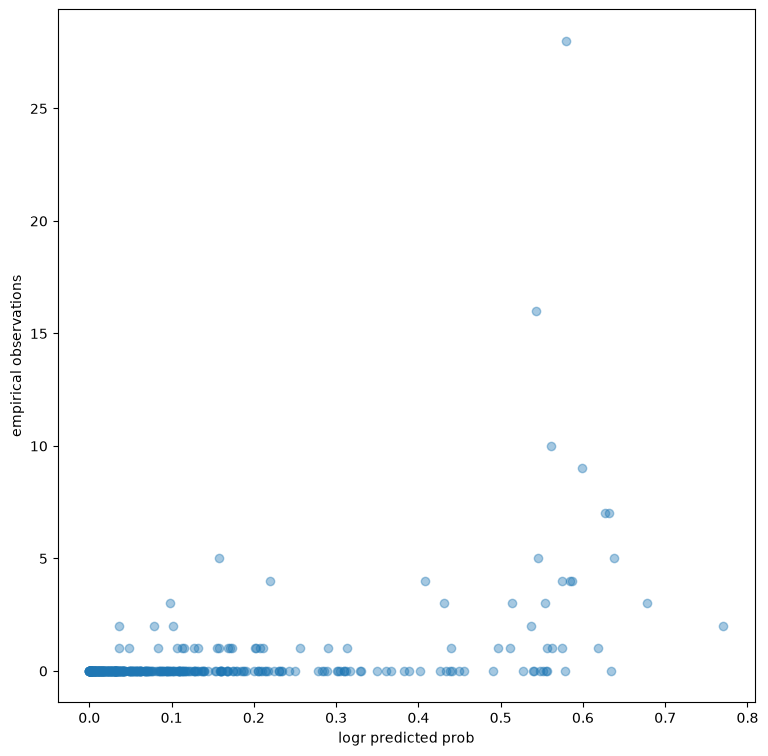

In [65]:
# I wonder if it would be better to separate distance in the statistic model.
fig, ax = plt.subplots(figsize = (9,9))
plt.scatter(gdf_DZ22_results["predicted_proba"], gdf_DZ22_results["empirical"], alpha = 0.4)
ax.set_xlabel("logr predicted prob")
ax.set_ylabel("empirical observations")

In [44]:
gdf_data.loc[:,["empirical", "predicted_proba"]].corr(method = 'spearman')
# This correlation is less good than the ABM, although we are not quite comparing apples with apples.

,empirical,predicted_proba
empirical,1.000000,0.246372
predicted_proba,0.246372,1.000000


In [27]:
gdf_data.loc[:,["empirical", "predicted_proba"]].corr(method = 'spearman')

,empirical,predicted_proba
empirical,1.000000,0.246372
predicted_proba,0.246372,1.000000


In [47]:
predicted_set = set(gdf_data.sort_values("predicted_proba", ascending = False).iloc[:20].index)
empirical_set = set(gdf_data.sort_values("empirical", ascending = False).iloc[:20].index)
predicted_set.intersection(empirical_set)

{'S00138806', 'S00138872', 'S00139009', 'S00139165', 'S00139272', 'S00139412'}

[]

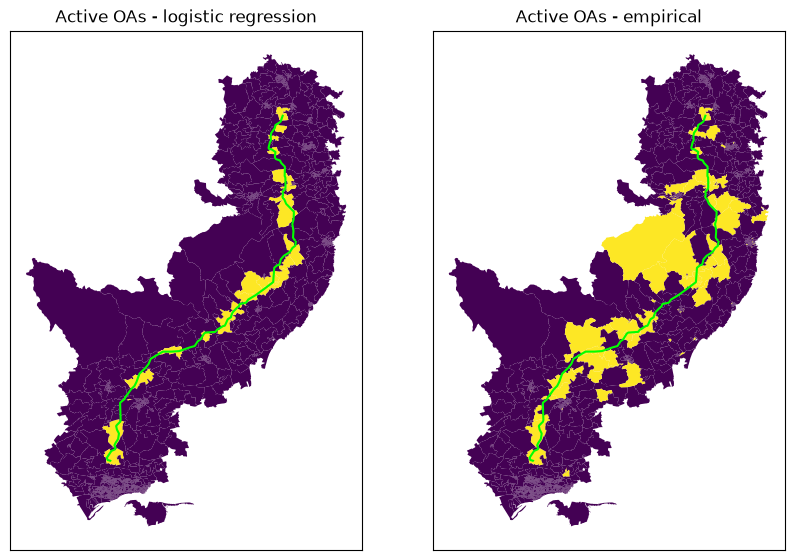

In [40]:
fig, ax = plt.subplots(figsize = (10,10), ncols = 2)
norm = mpl.colors.Normalize(vmin=0, vmax=8)
gdf_data.plot(column = "Y", ax = ax[1])
gdf_data.plot(column = "predicted", ax = ax[0])

gdf_kt_route.plot(ax = ax[0], color = 'lime')
gdf_kt_route.plot(ax = ax[1], color = 'lime')

ax[0].set_title("Active OAs - logistic regression")
ax[1].set_title("Active OAs - empirical")

ax[0].set_xticks([])
ax[0].set_yticks([])
ax[1].set_xticks([])
ax[1].set_yticks([])